# 02. Churn Modeling & Feature Interpretability
## E-Commerce Customer Churn & Lifetime Value (LTV) Predictor
This notebook trains baseline (Logistic Regression) and production (XGBoost with hyperparameter tuning) churn models, finds the optimal decision threshold, and analyzes feature importances via Tree SHAP.

In [1]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve, f1_score
from xgboost import XGBClassifier

sns.set_theme(style='whitegrid')
df = pd.read_csv('../data/processed/features.csv')
print('Features dataset shape:', df.shape)
df.head()

C:\Users\nites\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Features dataset shape: (5281, 20)


,CustomerID,Recency,Frequency,Monetary,AvgOrderValue,Tenure,AvgDaysBetweenOrders,UniqueProducts,ReturnRate,PurchasesLast30Days,PurchasesLast60Days,PurchasesLast90Days,Country,Churn,Country_EIRE,Country_France,Country_Germany,Country_Other,Country_Spain,Country_United Kingdom
0,12346,235,12,77556.46,6463.04,635,36.37,27,0.0,0,0,0,United Kingdom,1,0,0,0,0,0,1
1,12347,39,6,4114.18,685.70,313,54.95,107,0.0,0,1,1,Other,0,0,0,0,1,0,0
2,12348,158,4,1709.40,427.35,347,63.28,25,0.0,0,0,0,Other,0,0,0,0,1,0,0
3,12349,317,3,2671.14,890.38,498,90.90,90,0.0,0,0,0,Other,0,0,0,0,1,0,0
4,12350,219,1,334.40,334.40,219,219.00,17,0.0,0,0,0,Other,1,0,0,0,1,0,0


### 1. Train/Test Stratified Split (80/20)

In [2]:
feature_cols = [
    'Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'Tenure',
    'AvgDaysBetweenOrders', 'UniqueProducts', 'ReturnRate',
    'PurchasesLast30Days', 'PurchasesLast60Days', 'PurchasesLast90Days',
    'Country_United Kingdom', 'Country_Germany', 'Country_France',
    'Country_EIRE', 'Country_Spain', 'Country_Other'
]
X = df[feature_cols]
y = df['Churn'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(f'Train size: {X_train.shape}, Test size: {X_test.shape}')
print(f'Train churn rate: {y_train.mean():.2%}, Test churn rate: {y_test.mean():.2%}')

Train size: (4224, 17), Test size: (1057, 17)
Train churn rate: 56.61%, Test churn rate: 56.58%


### 2. Model Evaluation Comparison

In [3]:
with open('../models/metrics.json', 'r') as f:
    metrics = json.load(f)

metrics_df = pd.DataFrame([metrics['LogisticRegression'], metrics['XGBoost']], index=['Logistic Regression', 'XGBoost (Tuned)'])
metrics_df

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Optimal_Threshold
Logistic Regression,0.746452,0.753846,0.819398,0.785256,0.807765,0.833819,NaN
XGBoost (Tuned),0.751183,0.738265,0.867893,0.797848,0.819318,0.832646,0.44


### 3. Confusion Matrix and ROC Curve

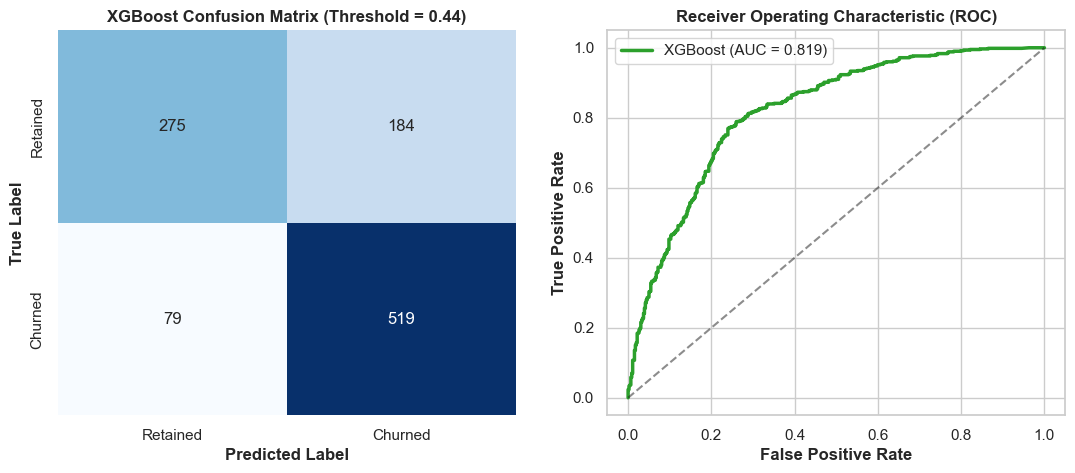

In [4]:
model_bundle = joblib.load('../models/churn_xgb.joblib')
best_xgb = model_bundle['model']
threshold = model_bundle['threshold']

probs = best_xgb.predict_proba(X_test)[:, 1]
preds = (probs >= threshold).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_test, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Retained', 'Churned'], yticklabels=['Retained', 'Churned'])
axes[0].set_title(f'XGBoost Confusion Matrix (Threshold = {threshold:.2f})', fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontweight='bold')
axes[0].set_ylabel('True Label', fontweight='bold')

fpr, tpr, _ = roc_curve(y_test, probs)
axes[1].plot(fpr, tpr, color='#2ca02c', linewidth=2.5, label=f'XGBoost (AUC = {roc_auc_score(y_test, probs):.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_title('Receiver Operating Characteristic (ROC)', fontweight='bold')
axes[1].set_xlabel('False Positive Rate', fontweight='bold')
axes[1].set_ylabel('True Positive Rate', fontweight='bold')
axes[1].legend()
plt.show()

### 4. SHAP Feature Attribution Analysis

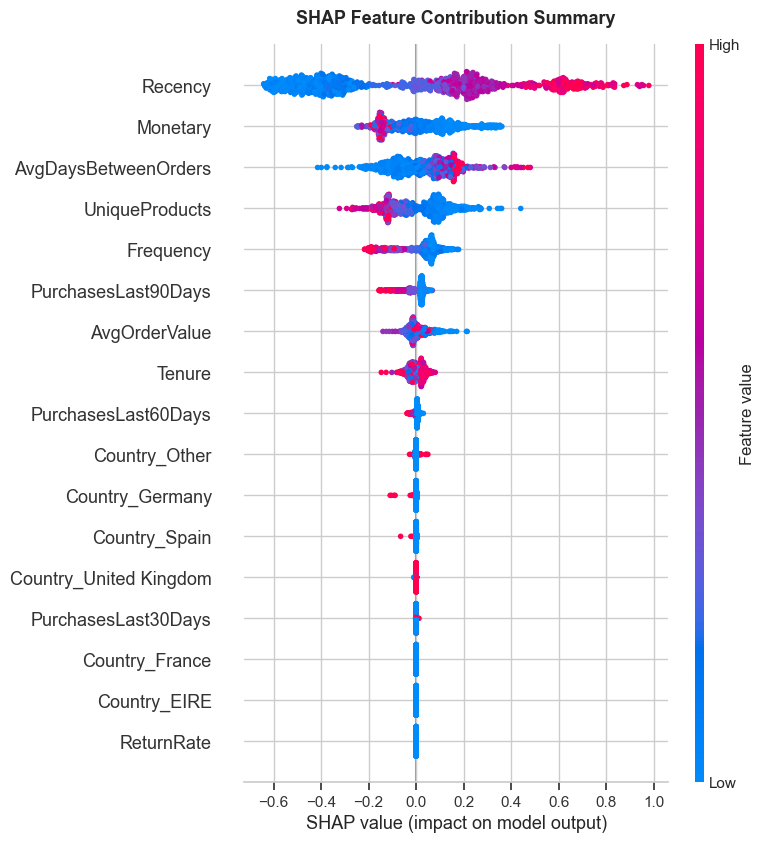

In [5]:
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test)
plt.figure(figsize=(9, 6))
shap.summary_plot(shap_values, X_test, feature_names=feature_cols, show=False)
plt.title('SHAP Feature Contribution Summary', fontsize=13, fontweight='bold', pad=15)
plt.show()